# Diwali Sales Analysis & Customer Segmentation

Analyze festive-season sales data to understand customer purchasing behavior, explore sales trends, and identify customer segments using K-Means clustering.

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

In [1]:
import sys
print(sys.executable)

c:\Users\soham\Documents\Diwali-Sales-Analysis\.venv\Scripts\python.exe


In [2]:
# Importing necessary libraries:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [3]:
# Visualization style
sns.set_theme(style="whitegrid", palette="pastel")

In [4]:
# Load the dataset
DATA_PATH = Path("data") / "Diwali Sales Data.csv"
df = pd.read_csv(DATA_PATH, encoding="cp1252")

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (11251, 15)


,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0,NaN,NaN
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0,NaN,NaN
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0,NaN,NaN
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0,NaN,NaN
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0,NaN,NaN


## Data Cleaning

In [5]:
# Insepect the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11251 entries, 0 to 11250
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11251 non-null  int64  
 1   Cust_name         11251 non-null  str    
 2   Product_ID        11251 non-null  str    
 3   Gender            11251 non-null  str    
 4   Age Group         11251 non-null  str    
 5   Age               11251 non-null  int64  
 6   Marital_Status    11251 non-null  int64  
 7   State             11251 non-null  str    
 8   Zone              11251 non-null  str    
 9   Occupation        11251 non-null  str    
 10  Product_Category  11251 non-null  str    
 11  Orders            11251 non-null  int64  
 12  Amount            11239 non-null  float64
 13  Status            0 non-null      float64
 14  unnamed1          0 non-null      float64
dtypes: float64(3), int64(4), str(8)
memory usage: 1.3 MB


In [6]:
# Remove empty columns and rows without purchase amounts
df = df.dropna(axis=1, how="all")
df = df.dropna(subset=["Amount"])

print("Dataset shape:", df.shape)
print("Missing values:\n", df.isnull().sum())

Dataset shape: (11239, 13)
Missing values:
 User_ID             0
Cust_name           0
Product_ID          0
Gender              0
Age Group           0
Age                 0
Marital_Status      0
State               0
Zone                0
Occupation          0
Product_Category    0
Orders              0
Amount              0
dtype: int64


In [7]:
# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 8


In [8]:
# Standardize column names
df.columns = (
    df.columns.str.strip().str.lower().str.replace(" ", "_")
)
print(df.columns.tolist())

['user_id', 'cust_name', 'product_id', 'gender', 'age_group', 'age', 'marital_status', 'state', 'zone', 'occupation', 'product_category', 'orders', 'amount']


In [9]:
# inspect duplicate records
duplicates = df[df.duplicated(keep=False)].sort_values(
    ["user_id", "product_id"]
)
print("Rows involved in duplicates:", len(duplicates))
display(duplicates)

Rows involved in duplicates: 16


,user_id,cust_name,product_id,gender,age_group,age,marital_status,state,zone,occupation,product_category,orders,amount
8650,1000083,Gute,P00242842,M,26-35,35,0,Uttar Pradesh,Central,Hospitality,Clothing & Apparel,3,5345.0
8651,1000083,Gute,P00242842,M,26-35,35,0,Uttar Pradesh,Central,Hospitality,Clothing & Apparel,3,5345.0
5907,1001260,Dheeraj,P00344042,M,26-35,28,0,Maharashtra,Western,IT Sector,Electronics & Gadgets,4,8015.0
5908,1001260,Dheeraj,P00344042,M,26-35,28,0,Maharashtra,Western,IT Sector,Electronics & Gadgets,4,8015.0
6172,1001325,Reese,P00111742,F,26-35,27,1,Gujarat,Western,Construction,Electronics & Gadgets,3,7923.0
6173,1001325,Reese,P00111742,F,26-35,27,1,Gujarat,Western,Construction,Electronics & Gadgets,3,7923.0
8940,1001476,Anudeep,P00036842,M,18-25,25,0,Maharashtra,Western,IT Sector,Clothing & Apparel,4,5202.0
8941,1001476,Anudeep,P00036842,M,18-25,25,0,Maharashtra,Western,IT Sector,Clothing & Apparel,4,5202.0
18,1001883,Praneet,P00029842,M,51-55,54,1,Uttar Pradesh,Central,Hospitality,Auto,1,23568.0
19,1001883,Praneet,P00029842,M,51-55,54,1,Uttar Pradesh,Central,Hospitality,Auto,1,23568.0


In [10]:
# Validate numeric columns
print(df[["age", "orders", "amount"]].describe())
print("Non-positive amounts:", (df["amount"] <= 0).sum())
print("Non-positive orders:", (df["orders"] <= 0).sum())

                age        orders        amount
count  11239.000000  11239.000000  11239.000000
mean      35.410357      2.489634   9453.610858
std       12.753866      1.114967   5222.355869
min       12.000000      1.000000    188.000000
25%       27.000000      2.000000   5443.000000
50%       33.000000      2.000000   8109.000000
75%       43.000000      3.000000  12675.000000
max       92.000000      4.000000  23952.000000
Non-positive amounts: 0
Non-positive orders: 0


In [11]:
# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)
print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())

Dataset shape: (11231, 13)
Duplicate rows: 0


In [12]:
# Final data quality check
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Rows: 11231
Columns: 13
Missing values: 0
Duplicate rows: 0


## Exploratory Data Analysis (EDA)
### 1. Sales Analysis by Gender

In [13]:

# Analyze sales by gender
gender_sales = df.groupby("gender")["amount"].agg(
    total_sales="sum",
    average_purchase="mean",
    customer_transactions="count"
).reset_index()

display(gender_sales.round(2))


,gender,total_sales,average_purchase,customer_transactions
0,F,74307682.43,9492.55,7828
1,M,31871146.00,9365.60,3403


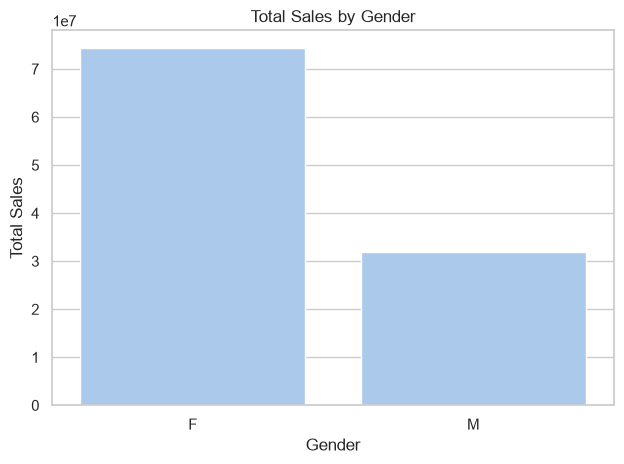

In [33]:

# Plot gender-wise sales
sns.barplot(data=gender_sales, x="gender", y="total_sales")
plt.title("Total Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.savefig("sales_by_gender.png", dpi=300, bbox_inches="tight")
plt.show()


### 2. Sales Analysis by Age Group

In [15]:

# Analyze sales by age group
age_sales = df.groupby("age_group").agg(
    total_sales=("amount", "sum"),
    average_purchase=("amount", "mean"),
    transactions=("amount", "count")
).reset_index()

display(age_sales.round(2))


,age_group,total_sales,average_purchase,transactions
0,0-17,2699653.00,9120.45,296
1,18-25,17235530.00,9177.60,1878
2,26-35,42581768.94,9387.52,4536
3,36-45,22135136.49,9699.88,2282
4,46-50,9207844.00,9367.08,983
5,51-55,8237909.00,9937.16,829
6,55+,4080987.00,9557.35,427


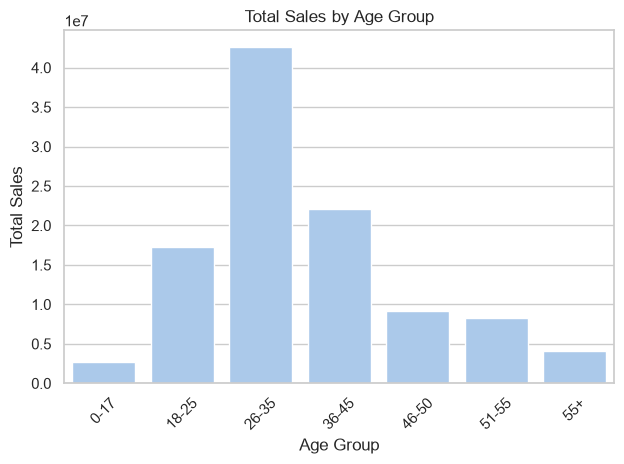

In [16]:

# Plot age-group sales
sns.barplot(
    data=age_sales,
    x="age_group",
    y="total_sales",
    order=["0-17", "18-25", "26-35", "36-45", "46-50", "51-55", "55+"]
)
plt.title("Total Sales by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 3. Sales by Gender and Age Group

In [17]:

# Analyze gender and age group
gender_age_sales = df.pivot_table(
    index="age_group",
    columns="gender",
    values="amount",
    aggfunc="sum",
    fill_value=0
)

display(gender_age_sales.round(2))


gender,F,M
age_group,,
0-17,1441409.00,1258244.0
18-25,11887003.00,5348527.0
26-35,30945639.94,11636129.0
36-45,15500098.49,6635038.0
46-50,6743393.00,2464451.0
51-55,5385208.00,2852701.0
55+,2404931.00,1676056.0


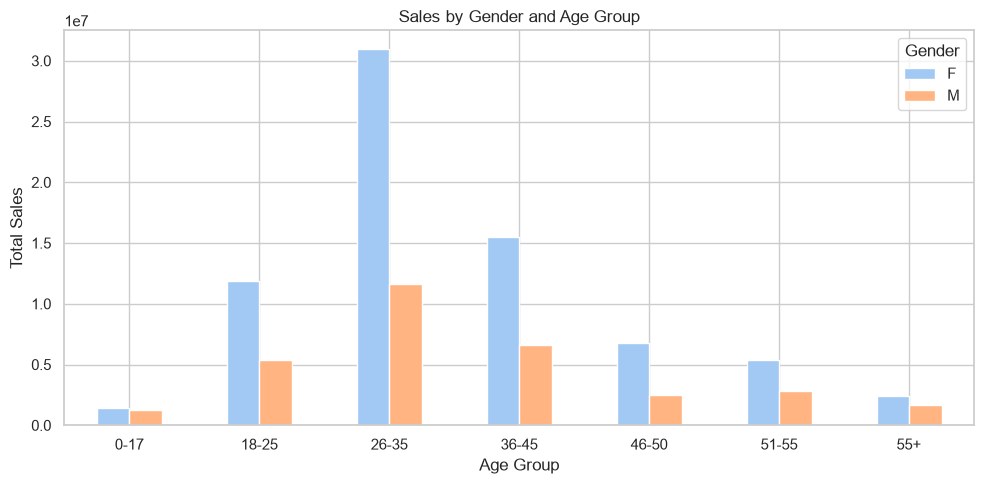

In [18]:

# Plot gender and age-group sales
gender_age_sales.plot(kind="bar", figsize=(10, 5))

plt.title("Sales by Gender and Age Group")
plt.xlabel("Age Group")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.legend(title="Gender")
plt.tight_layout()
plt.show()


### 4. State-wise Sales Analysis

In [19]:

# Analyze state-wise sales
state_sales = df.groupby("state").agg(
    total_sales=("amount", "sum"),
    transactions=("amount", "count")
).reset_index()

state_sales = state_sales.sort_values("total_sales", ascending=False)

display(state_sales.head(10).round(2))


,state,total_sales,transactions
14,Uttar Pradesh,19346055.00,1942
10,Maharashtra,14404467.00,1522
7,Karnataka,13523540.00,1304
2,Delhi,11603819.45,1104
9,Madhya Pradesh,8101142.00,921
0,Andhra Pradesh,8037146.99,811
5,Himachal Pradesh,4963368.00,608
4,Haryana,4217871.00,451
1,Bihar,4014669.00,433
3,Gujarat,3938159.00,426


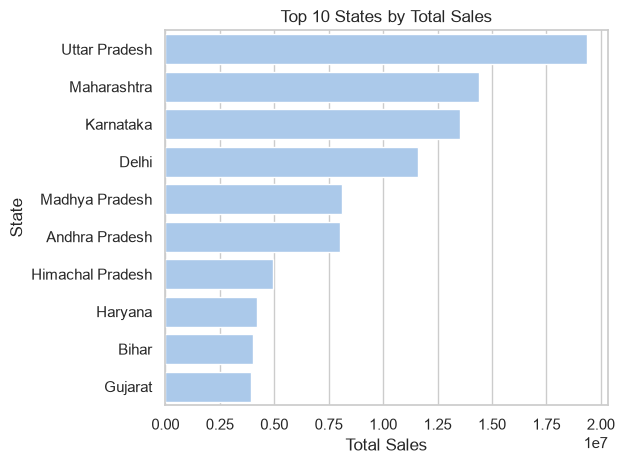

In [20]:

# Plot top 10 states
top_states = state_sales.head(10)

sns.barplot(data=top_states, x="total_sales", y="state")
plt.title("Top 10 States by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("State")
plt.tight_layout()
plt.show()


### 5. Sales Analysis by Occupation

In [21]:

# Analyze occupation-wise sales
occupation_sales = df.groupby("occupation").agg(
    total_sales=("amount", "sum"),
    average_purchase=("amount", "mean"),
    transactions=("amount", "count")
).reset_index()

occupation_sales = occupation_sales.sort_values(
    "total_sales", ascending=False
)

display(occupation_sales.round(2))


,occupation,total_sales,average_purchase,transactions
10,IT Sector,14741862.00,9324.39,1581
8,Healthcare,13034587.49,9257.52,1408
2,Aviation,12599994.00,9625.66,1309
3,Banking,10770610.95,9472.83,1137
7,Govt,8517212.00,9973.32,854
9,Hospitality,6337633.00,9053.76,700
12,Media,6295832.99,9883.57,637
1,Automobile,5368596.00,9501.94,565
4,Chemical,5297436.00,9791.93,541
11,Lawyer,4981665.00,9381.67,531


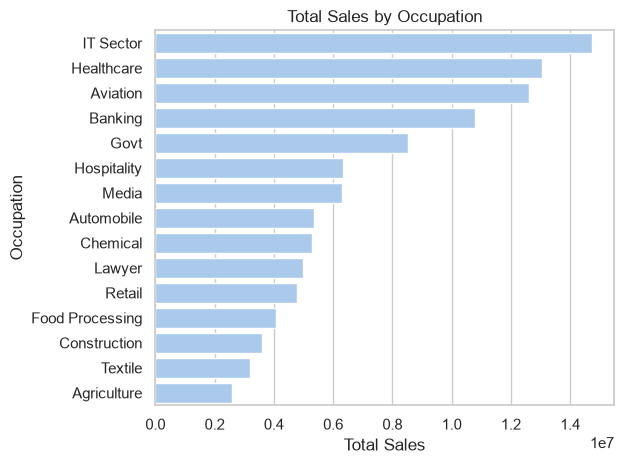

In [22]:

# Plot occupation-wise sales
sns.barplot(
    data=occupation_sales,
    x="total_sales",
    y="occupation"
)

plt.title("Total Sales by Occupation")
plt.xlabel("Total Sales")
plt.ylabel("Occupation")
plt.tight_layout()
plt.show()


### 6. Sales Analysis by Product Category

In [23]:

# Analyze product category sales
category_sales = df.groupby("product_category").agg(
    total_sales=("amount", "sum"),
    average_purchase=("amount", "mean"),
    transactions=("amount", "count")
).reset_index()

category_sales = category_sales.sort_values(
    "total_sales", ascending=False
)

display(category_sales.round(2))


,product_category,total_sales,average_purchase,transactions
6,Food,33933883.50,13628.07,2490
3,Clothing & Apparel,16484472.00,6213.52,2653
5,Electronics & Gadgets,15607657.00,7496.47,2082
7,Footwear & Shoes,15575209.45,14707.47,1059
8,Furniture,5440051.99,15454.69,352
9,Games & Toys,4331694.00,11222.01,386
14,Sports Products,3635933.00,10213.29,356
1,Beauty,1959484.00,4643.33,422
0,Auto,1935041.99,20156.69,96
15,Stationery,1676051.50,14964.75,112


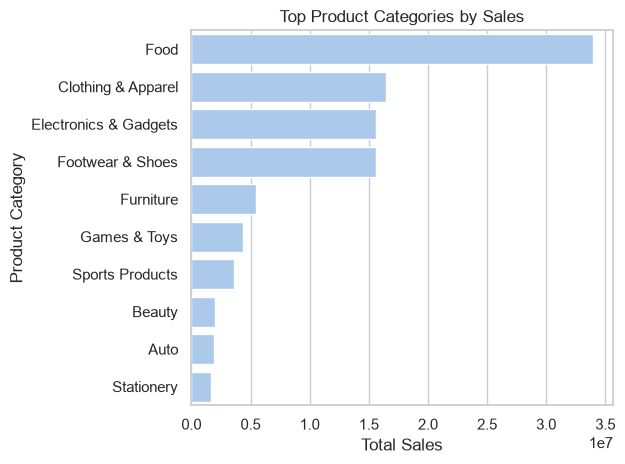

In [34]:

# Plot top product categories
top_categories = category_sales.head(10)

sns.barplot(
    data=top_categories,
    x="total_sales",
    y="product_category"
)

plt.title("Top Product Categories by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Category")
plt.tight_layout()
plt.savefig("product_category_sales.png", dpi=300, bbox_inches="tight")
plt.show()


## Customer Segmentation Using K-Means

In [25]:

# Create customer-level features
customer_summary = df.groupby("user_id").agg(
    total_spending=("amount", "sum"),
    transaction_count=("amount", "count"),
    average_spending=("amount", "mean")
).reset_index()

print("Unique customers:", len(customer_summary))
display(customer_summary.head())


Unique customers: 3752


,user_id,total_spending,transaction_count,average_spending
0,1000001,3977.0,1,3977.0
1,1000002,7098.0,1,7098.0
2,1000003,23714.0,2,11857.0
3,1000004,30381.0,2,15190.5
4,1000005,27667.0,2,13833.5


In [26]:

# Standardize customer features
features = customer_summary[
    ["total_spending", "transaction_count", "average_spending"]
]

scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)


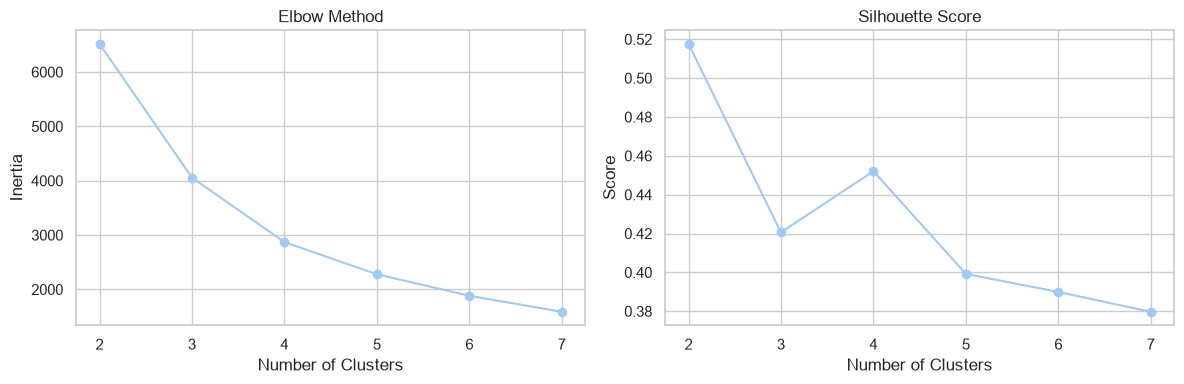

,clusters,inertia,silhouette_score
0,2,6517.064,0.518
1,3,4056.303,0.421
2,4,2870.348,0.452
3,5,2278.571,0.399
4,6,1883.450,0.390
5,7,1587.186,0.380


In [27]:

# Evaluate cluster counts
k_values = range(2, 8)
inertia = []
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(scaled_features)

    inertia.append(model.inertia_)
    silhouette_scores.append(silhouette_score(scaled_features, labels))

# Plot validation metrics
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(list(k_values), inertia, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(k_values), silhouette_scores, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters")
axes[1].set_ylabel("Score")

plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "clusters": list(k_values),
    "inertia": inertia,
    "silhouette_score": silhouette_scores
}).round(3))


In [28]:

# Fit the final K-Means model
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
customer_summary["cluster"] = kmeans.fit_predict(scaled_features)

print(customer_summary["cluster"].value_counts().sort_index())


cluster
0     580
1    3172
Name: count, dtype: int64


In [29]:

# Summarize customer segments
segment_summary = customer_summary.groupby("cluster").agg(
    customers=("user_id", "count"),
    total_spending=("total_spending", "sum"),
    average_spending=("average_spending", "mean"),
    average_transactions=("transaction_count", "mean")
).round(2)

display(segment_summary)


,customers,total_spending,average_spending,average_transactions
cluster,,,,
0,580,46365813.94,10113.93,8.08
1,3172,59813014.49,9316.04,2.06


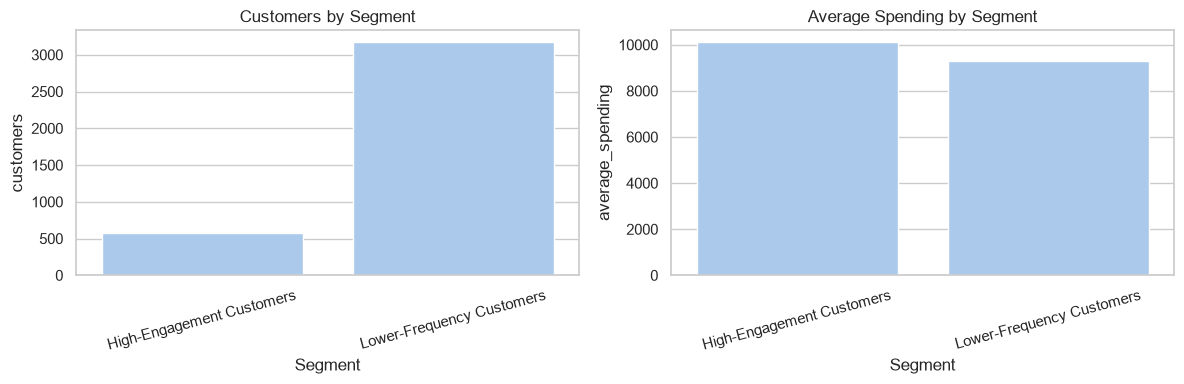

In [37]:
# Compare customer segments
plot_summary = customer_summary.groupby("segment").agg(
    customers=("user_id", "count"),
    average_spending=("average_spending", "mean")
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=plot_summary, x="segment", y="customers", ax=axes[0])
axes[0].set_title("Customers by Segment")
axes[0].set_xlabel("Segment")
axes[0].tick_params(axis="x", rotation=15)

sns.barplot(
    data=plot_summary, x="segment",
    y="average_spending", ax=axes[1]
)
axes[1].set_title("Average Spending by Segment")
axes[1].set_xlabel("Segment")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig("customer_segment_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [31]:

# Label customer segments
segment_names = {
    0: "High-Engagement Customers",
    1: "Lower-Frequency Customers"
}

customer_summary["segment"] = customer_summary["cluster"].map(segment_names)

display(customer_summary.head())


,user_id,total_spending,transaction_count,average_spending,cluster,segment
0,1000001,3977.0,1,3977.0,1,Lower-Frequency Customers
1,1000002,7098.0,1,7098.0,1,Lower-Frequency Customers
2,1000003,23714.0,2,11857.0,1,Lower-Frequency Customers
3,1000004,30381.0,2,15190.5,1,Lower-Frequency Customers
4,1000005,27667.0,2,13833.5,1,Lower-Frequency Customers


## Business Insights and Recommendations

In [32]:

# Summarize customer segments
segment_summary = customer_summary.groupby("segment").agg(
    customers=("user_id", "count"),
    total_spending=("total_spending", "sum"),
    average_customer_spending=("total_spending", "mean"),
    average_transactions=("transaction_count", "mean")
).round(2)

segment_summary["customer_share_pct"] = (
    segment_summary["customers"] / len(customer_summary) * 100
).round(2)

display(segment_summary)


,customers,total_spending,average_customer_spending,average_transactions,customer_share_pct
segment,,,,,
High-Engagement Customers,580,46365813.94,79941.06,8.08,15.46
Lower-Frequency Customers,3172,59813014.49,18856.56,2.06,84.54



## Conclusion

This project explored Diwali sales data through data cleaning, exploratory data analysis, and customer segmentation.

The analysis examined sales patterns across gender, age group, state, occupation, and product category. K-Means clustering identified two exploratory customer segments with different spending and transaction patterns.

The results suggest opportunities to investigate customer retention, repeat-purchase behavior, and targeted marketing strategies.

### Limitations

- The dataset covers a specific festive-sales context.
- Transaction records are used as a proxy for purchase frequency.
- The clustering results depend on the selected features and number of clusters.
- Further validation is required before applying the segments to real marketing decisions.
